# Figure 4 — Fingerprinting FC, MOU EC e DCM

Pipeline riproducibile: dati BOLD → FC salvate con ID → correlazioni di identificazione → accuratezza in funzione della numerosità → figura Matplotlib con stella DCM.

**Convenzioni:** Pearson; diagonali escluse dai vettori (non sostituite con zeri). FC: triangolo superiore della parte simmetrica; EC: tutti gli archi diretti. Identificazione RUN1 → RUN2 tramite argmax di riga. Sottocampionamento senza reinserimento con seed fisso, stesso numero di ripetizioni e barre ±3 SEM di Figure 4; queste barre non sono intervalli di confidenza.

**Ordine MOU non certificato:** gli array MOU non contengono ID. Il confronto run-to-run assume che le righe dei due file corrispondano agli stessi soggetti. Non vengono attribuiti ID ricostruiti alle matrici MOU. Il filtro 200 viene applicato in coppia ai due array MOU; le FC mantengono i loro ID reali e tutti i soggetti disponibili, come nelle curve originali. EC e FC non costituiscono quindi necessariamente coorti identiche.

Le FC usano filtro Butterworth ordine 2, 0.01–0.1 Hz, TR=0.72 s. Per 62 ROI si aggregano i segnali Schaefer100 mediante `clust_idx_LEMON`, poi si calcola FC (come `cluster_regions` + `calc_Corr0` di Figure 4; non la media dei blocchi FC della diversa analisi SSI). Qui si ricostruisce la pipeline filtrata; la cella esplorativa con `data_ref = data_1` non viene applicata.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import signal
from scipy.io import loadmat
import matplotlib.pyplot as plt
from matplotlib import cm, font_manager
from threadpoolctl import threadpool_limits

PROJECT = Path('/home/benedetta/Scripts/Insight_project')
DATA = PROJECT / 'numpy files'
BOLD = Path('/home/benedetta/hcp_parcellated')
OUT = DATA / 'Figure4_fingerprinting'
OUT.mkdir(exist_ok=True)
FC_CACHE_VERSION = 'filtered_cluster_signals_calcCorr0_v1'
RECOMPUTE_FC = False
SAMPLE_SIZES = [50, 100, 200, 300, 400, 500, 600, 700, 800, 953]
N_REALIZATIONS = 200
EC_FILES = {
 62: ['EC_matrix_HCP1_74.npy', 'EC_matrix_HCP2_74.npy'],
 100: ['JS_1_100_new.npy', 'JS_2_100_new.npy'],
 200: ['JS_1_200_new.npy', 'JS_2_200_new.npy']}
DCM_ROOT = Path('/readonly/insights/RESULTS_YA_new_1000')
DCM_EXCLUDE_IDS = {'119732', '119833', '140420'}  # Le tue esclusioni 70,71,146, convertite in ID.
TR = 0.72
BAND = (0.01, 0.1)
# Limita il parallelismo numerico del kernel; nessun nuovo fit dei modelli.
threadpool_limits(limits=4)
font = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams['font.size'] = 13


## 1. FC per soggetto e run, salvate con ID

In [2]:
def ts_path(sid, run, resolution):
    folder = BOLD if resolution == 100 else BOLD / 'Schaefer200+AAL'
    return folder / sid / f'{sid}_REST{run}_LR_Schaefer{resolution}+AAL.npy'

# Elenco base originale: entrambi i run Schaefer100 con 1200 volumi.
base_ids = []
for folder in sorted(BOLD.iterdir(), key=lambda p: p.name):
    sid = folder.name
    files = [ts_path(sid, r, 100) for r in (1, 2)]
    if all(f.exists() for f in files) and all(np.load(f, mmap_mode='r').shape[0] == 1200 for f in files):
        base_ids.append(sid)
base_ids = np.array(base_ids)
map62 = loadmat(PROJECT / 'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()[:100]
assert np.array_equal(np.unique(map62), np.arange(1, 63))
W62 = (map62[:, None] == np.arange(1, 63)).astype(float)
W62 /= W62.sum(axis=0)
b, a = signal.butter(2, BAND, btype='bandpass', fs=1/TR)

def calc_fc_like_figure4(Y):
    # Riproduce calc_Corr0: ultimo volume escluso, std ddof=0, divisore N-1.
    Z = Y[:-1] - Y[:-1].mean(axis=0)
    sd = Z.std(axis=0)
    if not np.isfinite(Z).all() or np.any(sd == 0):
        raise ValueError('Segnale non finito o costante')
    Z /= sd
    return Z.T @ Z / (len(Z)-1)

fc = {}
fc_audit = []
for n in [62, 100, 200]:
    resolution = 100 if n in [62, 100] else 200
    ids = []
    for sid in base_ids:
        files = [ts_path(sid, r, resolution) for r in (1, 2)]
        good = all(f.exists() for f in files)
        if good:
            shapes = [np.load(f, mmap_mode='r').shape for f in files]
            good = all(len(shape)==2 and shape[0]==1200 and shape[1]>=resolution for shape in shapes)
        fc_audit.append({'subject_id': sid, 'rois': n, 'included': good})
        if good: ids.append(sid)
    ids = np.array(ids)
    cache = OUT / f'FC_{n}_ROIs.npz'
    if cache.exists() and not RECOMPUTE_FC:
        with np.load(cache, allow_pickle=False) as saved:
            assert str(saved['version']) == FC_CACHE_VERSION
            assert np.array_equal(saved['subject_ids'], ids), 'Cohort changed: set RECOMPUTE_FC=True'
            fc[n] = {'ids': ids, 'RUN1': saved['RUN1'].copy(), 'RUN2': saved['RUN2'].copy()}
        print('Loaded FC cache', n, len(ids))
        continue
    values = {r: [] for r in (1, 2)}
    for k, sid in enumerate(ids):
        for run in (1, 2):
            X = np.load(ts_path(sid, run, resolution))[:, :resolution]
            Y = signal.filtfilt(b, a, X, axis=0)
            if n == 62: Y = Y @ W62
            values[run].append(calc_fc_like_figure4(Y))
        if (k+1)%200 == 0: print(f'FC {n}: {k+1}/{len(ids)}', flush=True)
    fc[n] = {'ids': ids, 'RUN1': np.stack(values[1]), 'RUN2': np.stack(values[2])}
    np.savez_compressed(cache, subject_ids=ids, RUN1=fc[n]['RUN1'], RUN2=fc[n]['RUN2'],
                        version=FC_CACHE_VERSION, TR=TR, band_hz=BAND, mapping62=map62)
    print('Saved', cache.name, fc[n]['RUN1'].shape, flush=True)
pd.DataFrame(fc_audit).to_csv(OUT / 'FC_subject_audit.csv', index=False)


FC 62: 200/1013


FC 62: 400/1013


FC 62: 600/1013


FC 62: 800/1013


FC 62: 1000/1013


...

FC 200: 400/1013


FC 200: 600/1013


FC 200: 800/1013


FC 200: 1000/1013


Saved FC_200_ROIs.npz (1013, 200, 200)


## 2. MOU EC e filtro 200 ROI

In [3]:
ec = {}
for n, names in EC_FILES.items():
    raw1, raw2 = [np.load(DATA/name, mmap_mode='r') for name in names]
    assert raw1.shape == raw2.shape and raw1.shape[1] >= n
    keep = np.ones(len(raw1), dtype=bool)
    if n == 200:
        # Filtro originale, massimo con segno (NON massimo assoluto).
        keep = (raw1.max(axis=(1, 2)) >= .03) & (raw2.max(axis=(1, 2)) >= .03)
    ec[n] = {'RUN1': np.array(raw1[keep, :n, :n]),
             'RUN2': np.array(raw2[keep, :n, :n]), 'source_indices': np.flatnonzero(keep)}
    if n == 200:
        pd.DataFrame({'array_index': np.arange(len(keep)), 'included': keep,
                      'max_RUN1': raw1.max(axis=(1,2)), 'max_RUN2': raw2.max(axis=(1,2))}).to_csv(
                      OUT / 'MOU_200_filter.csv', index=False)
    print(f'EC {n}: {keep.sum()}/{len(keep)}; FC {n}: {len(fc[n]["ids"])}')


EC 62: 1013/1013; FC 62: 1013


EC 100: 1013/1013; FC 100: 1013


EC 200: 953/1013; FC 200: 1013


## 3. Identificazione e curve di accuratezza

In [4]:
def identification(m1, m2, symmetric=False):
    assert m1.shape == m2.shape
    n = m1.shape[1]
    mask = np.triu(np.ones((n,n), dtype=bool), k=1) if symmetric else ~np.eye(n, dtype=bool)
    def features(m):
        if symmetric: m = .5*(m + m.transpose(0,2,1))
        X = np.asarray(m[:,mask], dtype=float)
        X -= X.mean(axis=1, keepdims=True)
        norms = np.linalg.norm(X, axis=1, keepdims=True)
        if not np.isfinite(X).all() or np.any(norms==0):
            raise ValueError('Nonfinite or constant connectivity profile; inspect input, do not replace NaNs')
        return X/norms
    X1, X2 = features(m1), features(m2)
    C = X1 @ X2.T
    # Cross-check of optimized Pearson implementation against np.corrcoef.
    k = min(4,len(m1))
    np.testing.assert_allclose(C[:k,:k], np.corrcoef(np.vstack([X1[:k],X2[:k]]))[:k,k:], atol=1e-12)
    return C

def accuracy(C):
    return 100*np.mean(C.argmax(axis=1)==np.arange(len(C)))

def curve(C, sizes, seed):
    rng=np.random.default_rng(seed)
    means, errors=[],[]
    for size in sizes:
        if size>len(C): means.append(np.nan); errors.append(np.nan); continue
        reps=max(int(np.ceil(N_REALIZATIONS/size*50)),3)
        vals=[]
        for _ in range(reps):
            ix=rng.choice(len(C),size=size,replace=False)
            vals.append(accuracy(C[np.ix_(ix,ix)]))
        means.append(np.mean(vals)); errors.append(np.std(vals,ddof=1)/np.sqrt(reps))
    return np.array(means),np.array(errors)

identification_matrices, curves, summary = {}, {}, []
for kind, datasets in [('EC',ec),('FC',fc)]:
    for i,n in enumerate([62,100,200]):
        C=identification(datasets[n]['RUN1'], datasets[n]['RUN2'], symmetric=(kind=='FC'))
        key=f'{kind}_{n}'
        identification_matrices[key]=C
        curves[key]=curve(C,SAMPLE_SIZES,(100 if kind=='EC' else 200)+i)
        summary.append({'method':kind,'ROIs':n,'subjects':len(C),'accuracy_RUN1_to_RUN2':accuracy(C)})
        print(key,'completed',len(C),accuracy(C),flush=True)


EC_62 completed 1013 92.10266535044423


EC_100 completed 1013 89.73346495557749


EC_200 completed 953 95.17313746065058


FC_62 completed 1013 53.307008884501485


FC_100 completed 1013 55.18262586377097


FC_200 completed 1013 70.18756169792695


## 4. DCM 62 ROI: abbinamento per ID e accuratezza

In [5]:
dcm_files = {run: {f.stem.removeprefix('EMmulti_HCP_'):f for f in (DCM_ROOT/folder).glob('EMmulti_HCP_*.mat')}
             for run,folder in [('RUN1','RESULTS_YA_new_1000_RUN1_noisevar'),('RUN2','RESULTS_YA_new_1000_RUN2')]}
dcm_common=sorted(dcm_files['RUN1'].keys() & dcm_files['RUN2'].keys())
dcm_ids=np.array([sid for sid in dcm_common if sid not in DCM_EXCLUDE_IDS])
dcm_A={run:np.stack([loadmat(files[sid],variable_names=['A'])['A'][:62,:62] for sid in dcm_ids])
       for run,files in dcm_files.items()}
dcm_C=identification(dcm_A['RUN1'],dcm_A['RUN2'],symmetric=False)
dcm_n=len(dcm_ids)
dcm_accuracy=accuracy(dcm_C)
summary.append({'method':'DCM','ROIs':62,'subjects':dcm_n,'accuracy_RUN1_to_RUN2':dcm_accuracy})
pd.DataFrame({'subject_id':dcm_common,'included':[s not in DCM_EXCLUDE_IDS for s in dcm_common]}).to_csv(
    OUT/'DCM_subject_audit.csv',index=False)
summary=pd.DataFrame(summary)
display(summary)
print(f'DCM: {dcm_accuracy:.2f}% ({int(np.sum(dcm_C.argmax(axis=1)==np.arange(dcm_n)))}/{dcm_n})')


,method,ROIs,subjects,accuracy_RUN1_to_RUN2
0,EC,62,1013,92.102665
1,EC,100,1013,89.733465
2,EC,200,953,95.173137
3,FC,62,1013,53.307009
4,FC,100,1013,55.182626
5,FC,200,1013,70.187562
6,DCM,62,144,97.222222


DCM: 97.22% (140/144)


## 5. Figura finale: curve, distribuzioni e stella DCM

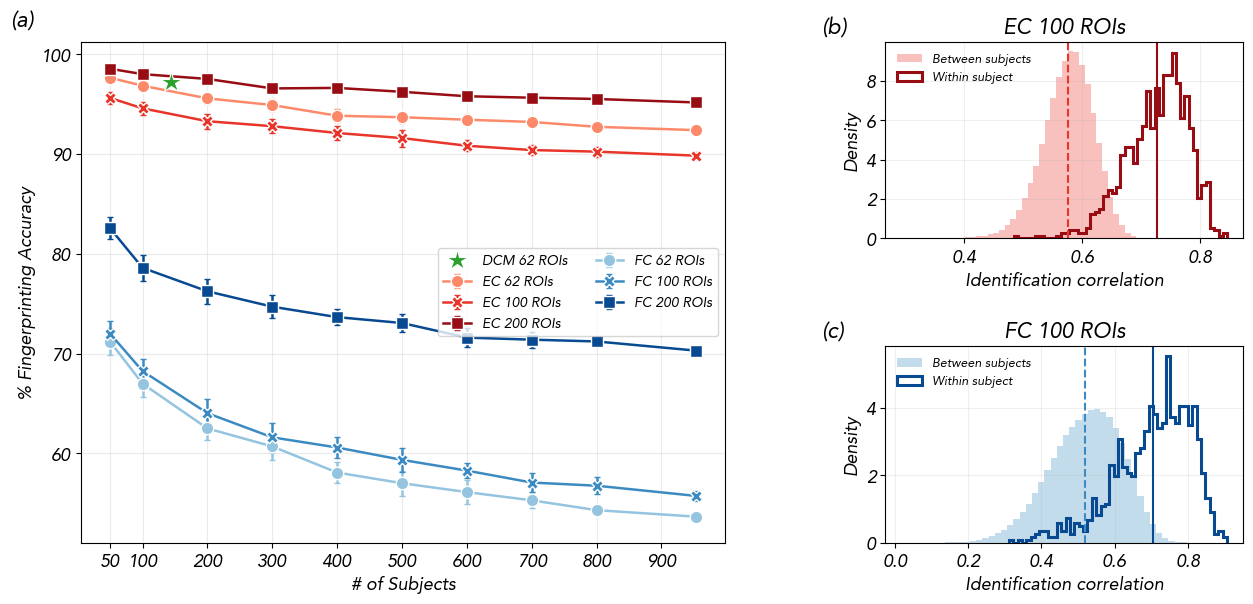

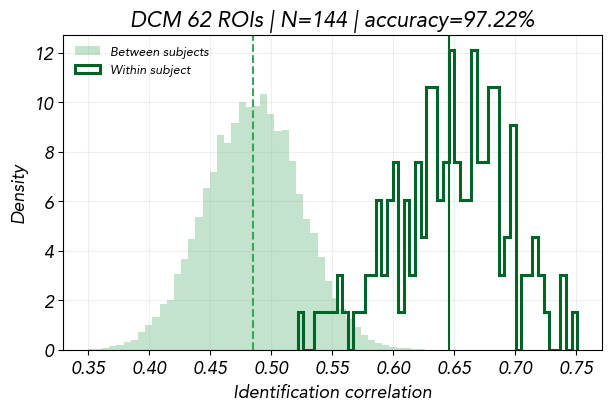

FC, risultati, audit e figure salvati in: /home/benedetta/Scripts/Insight_project/numpy files/Figure4_fingerprinting


In [6]:
reds=cm.Reds(np.linspace(.4,.9,3)); blues=cm.Blues(np.linspace(.4,.9,3))
markers=['o','X','s']
fig=plt.figure(figsize=(15,6.5))
gs=fig.add_gridspec(2,2,width_ratios=[1.8,1],wspace=.32,hspace=.55)
ax_curve=fig.add_subplot(gs[:,0]); ax_ec=fig.add_subplot(gs[0,1]); ax_fc=fig.add_subplot(gs[1,1])
for kind,colors in [('EC',reds),('FC',blues)]:
    for i,n in enumerate([62,100,200]):
        mean,sem=curves[f'{kind}_{n}']
        ax_curve.errorbar(SAMPLE_SIZES,mean,yerr=3*sem,fmt='-'+markers[i],color=colors[i],
                          markeredgecolor='white',capsize=2,markersize=9,linewidth=1.8,label=f'{kind} {n} ROIs')
# Stella calcolata: coordinate dai dati, non inserita su un'immagine.
ax_curve.plot(dcm_n,dcm_accuracy,marker='*',linestyle='none',markersize=16,color='#2ca02c',
              markeredgecolor='white',markeredgewidth=.8,label='DCM 62 ROIs',zorder=10)
ax_curve.set(xlabel='# of Subjects',ylabel='% Fingerprinting Accuracy')
ax_curve.set_xticks([50,100,200,300,400,500,600,700,800,900])
ax_curve.legend(fontsize=10,ncol=2,loc='best'); ax_curve.grid(alpha=.25)
ax_curve.text(-.11,1.03,'(a)',transform=ax_curve.transAxes,fontsize=16)

def plot_distributions(ax,C,title,colors):
    self_values=np.diag(C); others=C[~np.eye(len(C),dtype=bool)]
    ax.hist(others,bins=50,density=True,histtype='stepfilled',alpha=.3,color=colors[1],label='Between subjects')
    ax.hist(self_values,bins=50,density=True,histtype='step',linewidth=2.2,color=colors[2],label='Within subject')
    ax.axvline(others.mean(),color=colors[1],linestyle='--',linewidth=1.5)
    ax.axvline(self_values.mean(),color=colors[2],linewidth=1.5)
    ax.set(title=title,xlabel='Identification correlation',ylabel='Density')
    ax.legend(frameon=False,fontsize=9); ax.grid(alpha=.2)
plot_distributions(ax_ec,identification_matrices['EC_100'],'EC 100 ROIs',reds)
plot_distributions(ax_fc,identification_matrices['FC_100'],'FC 100 ROIs',blues)
for ax,label in [(ax_ec,'(b)'),(ax_fc,'(c)')]:ax.text(-.18,1.04,label,transform=ax.transAxes,fontsize=16)
fig.savefig(OUT/'Fingerprinting_with_identification_distributions_DCM.jpg',dpi=300,bbox_inches='tight')
plt.show()

fig_dcm,ax_dcm=plt.subplots(figsize=(6,4),constrained_layout=True)
plot_distributions(ax_dcm,dcm_C,f'DCM 62 ROIs | N={dcm_n} | accuracy={dcm_accuracy:.2f}%',cm.Greens(np.linspace(.4,.9,3)))
fig_dcm.savefig(OUT/'DCM_identification_distributions.jpg',dpi=300,bbox_inches='tight')
plt.show()

summary.to_csv(OUT/'accuracy_summary.csv',index=False)
payload={'sample_sizes':SAMPLE_SIZES,'dcm_ids':dcm_ids,'dcm_identification':dcm_C,'dcm_accuracy':dcm_accuracy}
for key,C in identification_matrices.items():
    payload[key+'_identification']=C
    payload[key+'_mean'],payload[key+'_sem']=curves[key]
for n in [62,100,200]:payload[f'EC_{n}_source_indices']=ec[n]['source_indices']
np.savez_compressed(OUT/'fingerprinting_results.npz',**payload)
print('FC, risultati, audit e figure salvati in:',OUT)


## Solo plot dai risultati salvati

Esegui soltanto la cella seguente, anche dopo il riavvio del kernel. Carica mean, SEM e matrici di identificazione da `fingerprinting_results.npz`, ricrea entrambe le figure e aggiorna gli stessi JPG. Nessun caricamento BOLD o ricalcolo delle correlazioni.

In [10]:
OUT

PosixPath('/home/benedetta/Scripts/Insight_project/numpy files/Figure4_fingerprinting')

In [9]:
with np.load(OUT/'fingerprinting_results.npz') as dati:
    print(dati.files)

['sample_sizes', 'dcm_ids', 'dcm_identification', 'dcm_accuracy', 'EC_62_identification', 'EC_62_mean', 'EC_62_sem', 'EC_100_identification', 'EC_100_mean', 'EC_100_sem', 'EC_200_identification', 'EC_200_mean', 'EC_200_sem', 'FC_62_identification', 'FC_62_mean', 'FC_62_sem', 'FC_100_identification', 'FC_100_mean', 'FC_100_sem', 'FC_200_identification', 'FC_200_mean', 'FC_200_sem', 'EC_62_source_indices', 'EC_100_source_indices', 'EC_200_source_indices']


Caricati mean e SEM da fingerprinting_results.npz. Barre: +/-3 SEM; nessun nuovo calcolo di fingerprinting.


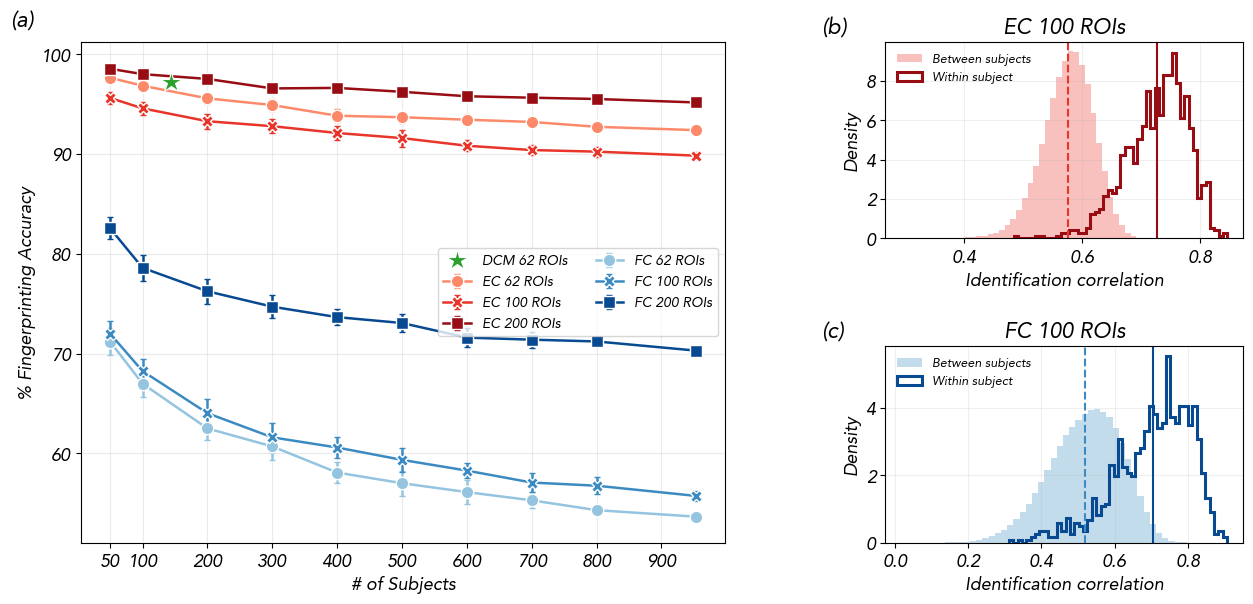

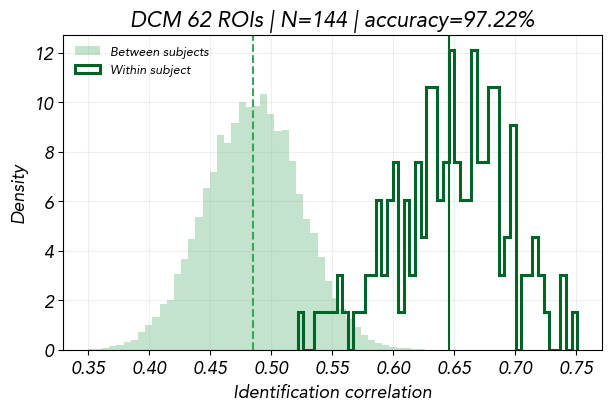

In [3]:
# Cella autonoma: può essere eseguita dopo Restart Kernel senza le celle precedenti.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, font_manager

PROJECT = Path('/home/benedetta/Scripts/Insight_project')
OUT = PROJECT / 'numpy files/Figure4_fingerprinting'
result_file = OUT / 'fingerprinting_results.npz'
if not result_file.exists():
    raise FileNotFoundError(f'Risultati mancanti: {result_file}. Eseguire prima la pipeline di calcolo.')
with np.load(result_file, allow_pickle=False) as saved:
    SAMPLE_SIZES = saved['sample_sizes'].copy()
    curves = {}
    identification_matrices = {}
    for kind in ['EC', 'FC']:
        for n in [62, 100, 200]:
            key = f'{kind}_{n}'
            curves[key] = (saved[key+'_mean'].copy(), saved[key+'_sem'].copy())
            identification_matrices[key] = saved[key+'_identification'].copy()
    dcm_ids = saved['dcm_ids'].copy()
    dcm_n = len(dcm_ids)
    dcm_C = saved['dcm_identification'].copy()
    dcm_accuracy = float(saved['dcm_accuracy'])
assert dcm_C.shape == (dcm_n, dcm_n)
font = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams['font.size'] = 13
print(f'Caricati mean e SEM da {result_file.name}. Barre: +/-3 SEM; nessun nuovo calcolo di fingerprinting.')

reds=cm.Reds(np.linspace(.4,.9,3)); blues=cm.Blues(np.linspace(.4,.9,3))
markers=['o','X','s']
fig=plt.figure(figsize=(15,6.5))
gs=fig.add_gridspec(2,2,width_ratios=[1.8,1],wspace=.32,hspace=.55)
ax_curve=fig.add_subplot(gs[:,0]); ax_ec=fig.add_subplot(gs[0,1]); ax_fc=fig.add_subplot(gs[1,1])
for kind,colors in [('EC',reds),('FC',blues)]:
    for i,n in enumerate([62,100,200]):
        mean,sem=curves[f'{kind}_{n}']
        ax_curve.errorbar(SAMPLE_SIZES,mean,yerr=3*sem,fmt='-'+markers[i],color=colors[i],
                          markeredgecolor='white',capsize=2,markersize=9,linewidth=1.8,label=f'{kind} {n} ROIs')
# Stella calcolata: coordinate dai dati, non inserita su un'immagine.
ax_curve.plot(dcm_n,dcm_accuracy,marker='*',linestyle='none',markersize=16,color='#2ca02c',
              markeredgecolor='white',markeredgewidth=.8,label='DCM 62 ROIs',zorder=10)
ax_curve.set(xlabel='# of Subjects',ylabel='% Fingerprinting Accuracy')
ax_curve.set_xticks([50,100,200,300,400,500,600,700,800,900])
ax_curve.legend(fontsize=10,ncol=2,loc='best'); ax_curve.grid(alpha=.25)
ax_curve.text(-.11,1.03,'(a)',transform=ax_curve.transAxes,fontsize=16)

def plot_distributions(ax,C,title,colors):
    self_values=np.diag(C); others=C[~np.eye(len(C),dtype=bool)]
    ax.hist(others,bins=50,density=True,histtype='stepfilled',alpha=.3,color=colors[1],label='Between subjects')
    ax.hist(self_values,bins=50,density=True,histtype='step',linewidth=2.2,color=colors[2],label='Within subject')
    ax.axvline(others.mean(),color=colors[1],linestyle='--',linewidth=1.5)
    ax.axvline(self_values.mean(),color=colors[2],linewidth=1.5)
    ax.set(title=title,xlabel='Identification correlation',ylabel='Density')
    ax.legend(frameon=False,fontsize=9); ax.grid(alpha=.2)
plot_distributions(ax_ec,identification_matrices['EC_100'],'EC 100 ROIs',reds)
plot_distributions(ax_fc,identification_matrices['FC_100'],'FC 100 ROIs',blues)
for ax,label in [(ax_ec,'(b)'),(ax_fc,'(c)')]:ax.text(-.18,1.04,label,transform=ax.transAxes,fontsize=16)
fig.savefig(OUT/'Fingerprinting_with_identification_distributions_DCM.jpg',dpi=300,bbox_inches='tight')
plt.show()

fig_dcm,ax_dcm=plt.subplots(figsize=(6,4),constrained_layout=True)
plot_distributions(ax_dcm,dcm_C,f'DCM 62 ROIs | N={dcm_n} | accuracy={dcm_accuracy:.2f}%',cm.Greens(np.linspace(.4,.9,3)))
fig_dcm.savefig(OUT/'DCM_identification_distributions.jpg',dpi=300,bbox_inches='tight')
plt.show()

